# Esploriamo Iris con Gemini · soluzione
**Script intelligenti: sviluppare modelli di Machine Learning con il codice** · 27/10/2026

Oggi non scriviamo codice a mano: lo scrive **Gemini**, l'assistente di Colab. Il nostro lavoro è chiedere bene e
controllare il risultato.

| | |
|---|---|
| **1 · Chiedi chiaro** | che cosa vuoi, con quali dati, in che forma vuoi il risultato |
| **2 · Leggi** | il codice proposto, anche senza capirlo tutto: quali dati usa? che cosa calcola? |
| **3 · Esegui** | e guarda che cosa succede, errori compresi |
| **4 · Controlla** | il risultato torna con quello che sai? I numeri sono plausibili? |

> **Prima di tutto:** *File → Salva una copia in Drive*, poi lavorate sulla vostra copia. Senza la copia le
> modifiche non si salvano.

> **Versione per il docente.** Ogni tappa ha il codice di una soluzione possibile, già eseguito. Gemini
> scriverà codice diverso, a volte con nomi diversi: va bene, conta che i risultati tornino.

## Come chiedere a Gemini
1. In una cella di codice vuota, cliccate su **genera** (oppure aprite il pannello di Gemini, in alto a destra).
2. Scrivete la richiesta in italiano: potete copiare il prompt di esempio.
3. Leggete il codice proposto prima di accettarlo.
4. Eseguitelo con ▶ e guardate il risultato.

*Se Gemini non è disponibile:* usate ChatGPT o Claude in un'altra scheda e incollate qui il codice.

## Preparazione
Eseguite questa cella con ▶: scarica il file `iris.csv` con le misure dei 150 fiori. È lo stesso file della
cartella del corso. Se il download non funziona, caricatelo a mano dal pannello **File** (l'icona a forma di cartella
a sinistra).

In [1]:
# Scarica il file iris.csv (la versione UCI del dataset Iris, 150 fiori) nella cartella di lavoro di Colab.
import os
import urllib.request

if not os.path.exists("iris.csv"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/matteolimoncini/script-intelligenti/main/incontro-1/dati/iris.csv", "iris.csv")
print("File iris.csv pronto")

File iris.csv pronto


## Tappa 1 · Caricare ed esplorare i dati
**Prompt di esempio** (copiatelo in Gemini):

> Con pandas, carica il file iris.csv e mostrami le prime righe. Poi dimmi quante righe e quante colonne ha, e
> quanti fiori ci sono per ogni specie.

In [2]:
import pandas as pd

df = pd.read_csv("iris.csv")
print("Righe e colonne:", df.shape)
print()
print(df["Species"].value_counts())
df.head()

Righe e colonne: (150, 6)

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


**Controllate**
- Ci sono 150 righe e 6 colonne? E 50 fiori per specie?
- Quali colonne sono **feature** (ciò che il modello guarda)? Qual è la **label** (ciò che vogliamo prevedere)?
  E la colonna `Id`?
- Quali funzioni di pandas ha usato Gemini? (`read_csv`, `head`, `shape`, `value_counts`…)
- Quali colonne sono numeri e quale è testo? Provate a chiedere: *«Mostrami i tipi di dati delle colonne»*.

In [3]:
# i tipi di dati: Id è un numero intero (int64), le quattro misure sono decimali (float64), Species è testo (object)
df.dtypes

Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object

**Che cosa si deve vedere:** 150 righe e 6 colonne, 50 fiori per specie. Feature: le quattro misure
(`SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`). Label: `Species`. La colonna `Id` è solo un numero
progressivo: non dice niente del fiore, quindi non è una feature. Se la usassimo, il modello imparerebbe l'ordine
delle righe (nel file i fiori sono ordinati per specie), non le misure.

**Possibile intoppo:** Gemini a volte carica Iris da seaborn o da scikit-learn invece che dal file. Funziona lo
stesso (con scikit-learn la specie compare come numero 0, 1, 2), ma è il momento giusto per chiedere: da dove
arrivano i dati che stiamo usando? E che cosa vuol dire quel numero?

## Tappa 2 · Un grafico e una domanda
**Prompt di esempio:**

> Con pandas e matplotlib, fai un grafico a dispersione con la lunghezza del petalo sull'asse x e la larghezza del
> petalo sull'asse y, con un colore diverso per ogni specie.

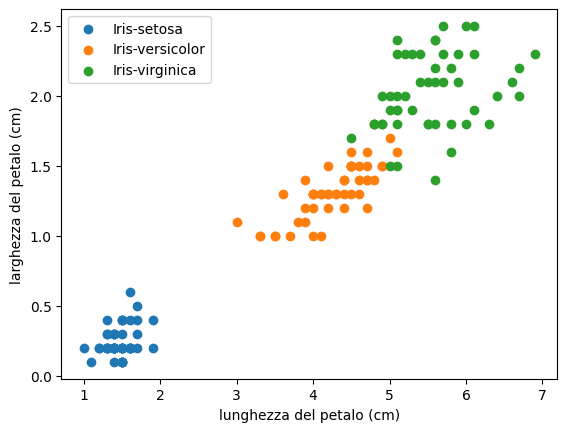

In [4]:
import matplotlib.pyplot as plt

colori = {"Iris-setosa": "tab:blue", "Iris-versicolor": "tab:orange", "Iris-virginica": "tab:green"}
for specie, gruppo in df.groupby("Species"):
    plt.scatter(gruppo["PetalLengthCm"], gruppo["PetalWidthCm"], label=specie, color=colori[specie])
plt.xlabel("lunghezza del petalo (cm)")
plt.ylabel("larghezza del petalo (cm)")
plt.legend()
plt.show()

**Se avanza tempo:**

> Fai una matrice di grafici a dispersione con tutte le coppie di misure (scatter_matrix di pandas), colorata per
> specie.

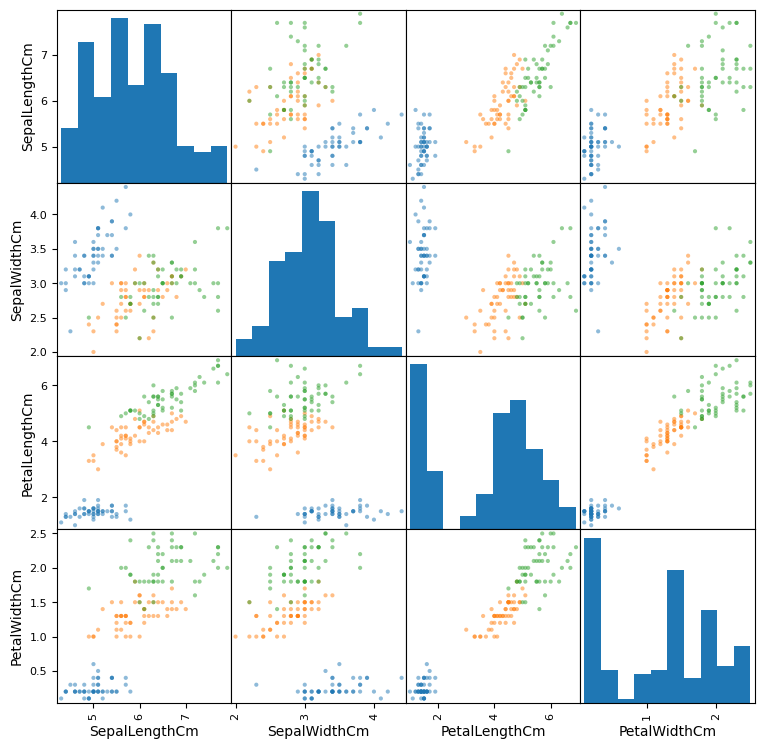

In [5]:
from pandas.plotting import scatter_matrix

# Id non è una misura del fiore: si toglie insieme alla specie
scatter_matrix(df.drop(columns=["Id", "Species"]), c=df["Species"].map(colori), figsize=(9, 9), diagonal="hist")
plt.show()

**Domande**
- Quale misura distingue meglio le specie?
- Le regole che avete scritto sulla scheda si vedono nel grafico? Dove passerebbe la soglia?
- Dove si confondono le specie? Lì un modello sbaglierà più facilmente.

**Che cosa si deve vedere:** la setosa è separata da tutte le altre; versicolor e virginica si
toccano e si sovrappongono un po'. Le misure del petalo separano meglio di quelle del sepalo. La soglia di 2,5 cm
sulla lunghezza del petalo cade nel vuoto tra la setosa e le altre due specie.

## Per chi finisce prima · La regola sui 150 fiori
Sulla scheda avete trovato una regola come *«petalo più corto di 2,5 cm → setosa»*. Funziona su tutti i fiori?

> Aggiungi una colonna «Previsione» che vale "Iris-setosa" se la lunghezza del petalo è minore di 2,5 e "non
> setosa" altrimenti. Poi fai una tabella che confronta la specie vera con la previsione.

In [6]:
# la regola trovata sulla scheda: petalo più corto di 2,5 cm -> setosa
df["Previsione"] = (df["PetalLengthCm"] < 2.5).map({True: "Iris-setosa", False: "non setosa"})
pd.crosstab(df["Species"], df["Previsione"])

Previsione,Iris-setosa,non setosa
Species,,
Iris-setosa,50,0
Iris-versicolor,0,50
Iris-virginica,0,50


**Che cosa si deve vedere:** le 50 setosa finiscono tutte in «Iris-setosa», le altre 100 tutte in «non
setosa»: la regola non sbaglia nessun fiore. Per versicolor e virginica invece nessuna soglia singola è perfetta: è
il problema da cui riparte l'incontro 2 (alberi di decisione e vicini).

## Per finire
Avete caricato un dataset, riconosciuto feature e label, fatto un grafico e controllato una regola: sono i primi
passi del ciclo di vita di un modello. **Nell'incontro 2** il computer troverà da solo le regole, con un albero di
decisione e con i vicini più vicini (KNN).